# Matplotlib Revision Cheat Sheet for AI/ML

A runnable notebook for exploratory, model-evaluation, and presentation charts.

**Recommended interface:** use `fig, ax = plt.subplots()` and call methods on `ax`. Every argument used below is explained next to the function call.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors, ticker
print("Matplotlib ready")


Matplotlib ready


## 1. Figure and Axes


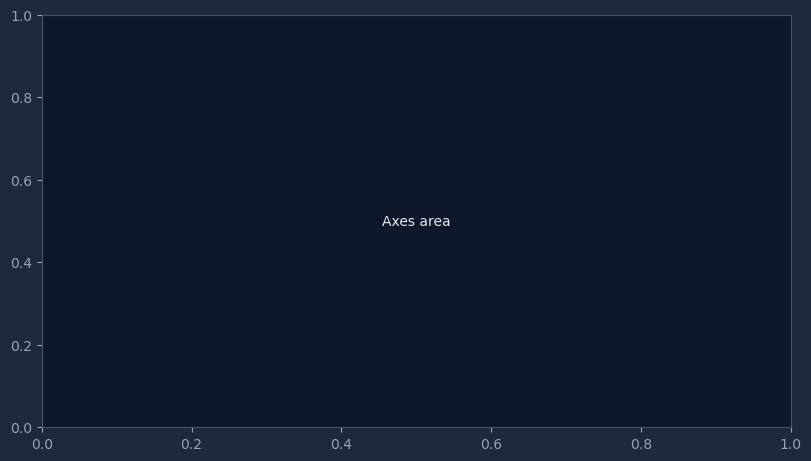

In [2]:
fig, ax = plt.subplots(
    nrows=1,                      # nrows: number of subplot rows
    ncols=1,                      # ncols: number of subplot columns
    figsize=(8, 4.5),             # figsize: figure width and height in inches
    dpi=100,                      # dpi: display dots per inch
    sharex=False,                 # sharex: subplots share x-axis limits/ticks when True
    sharey=False,                 # sharey: subplots share y-axis limits/ticks when True
    layout="constrained",         # layout: automatically reduce label overlap
    facecolor="white"             # facecolor: figure background color
)
ax.text(0.5, 0.5, "Axes area", ha="center", va="center", transform=ax.transAxes)
# x,y: text position
# ha/va: horizontal/vertical alignment
# transform=ax.transAxes: interpret x,y in axes fractions from 0 to 1
plt.show()


## 2. Line plot


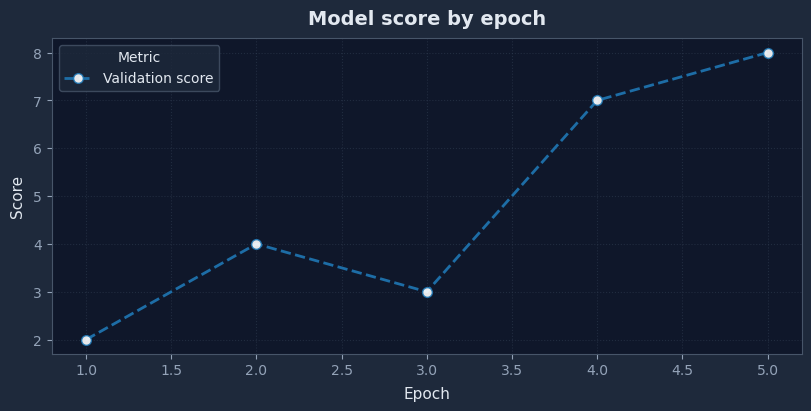

In [3]:
x = np.arange(1, 6)
y = np.array([2, 4, 3, 7, 8])
fig, ax = plt.subplots(figsize=(8,4), layout="constrained")
ax.plot(
    x,                            # x: horizontal coordinates
    y,                            # y: vertical coordinates
    color="tab:blue",             # color: line/marker color; accepts names, hex, RGB(A)
    linestyle="--",               # linestyle: '-', '--', '-.', ':', etc.
    linewidth=2,                  # linewidth: line thickness in points
    marker="o",                   # marker: symbol drawn at each data point
    markersize=7,                 # markersize: marker size in points
    markerfacecolor="white",      # markerfacecolor: marker interior color
    markeredgecolor="tab:blue",   # markeredgecolor: marker border color
    alpha=0.9,                    # alpha: opacity from 0 to 1
    label="Validation score",      # label: legend entry text
    zorder=3                      # zorder: larger values draw on top
)
ax.set_title("Model score by epoch", fontsize=14, fontweight="bold", loc="center", pad=10)
# label: title text; fontsize: text size; fontweight: weight; loc: alignment; pad: spacing in points
ax.set_xlabel("Epoch", fontsize=11, labelpad=6)  # labelpad: axis-label distance from axis
ax.set_ylabel("Score", fontsize=11, labelpad=6)
ax.legend(loc="best", frameon=True, title="Metric")
# loc: legend placement; frameon: show box; title: legend heading
ax.grid(visible=True, which="major", axis="both", linestyle=":", alpha=0.5)
# visible: show grid; which: major/minor/both ticks; axis: x/y/both
plt.show()


## 3. Scatter plot


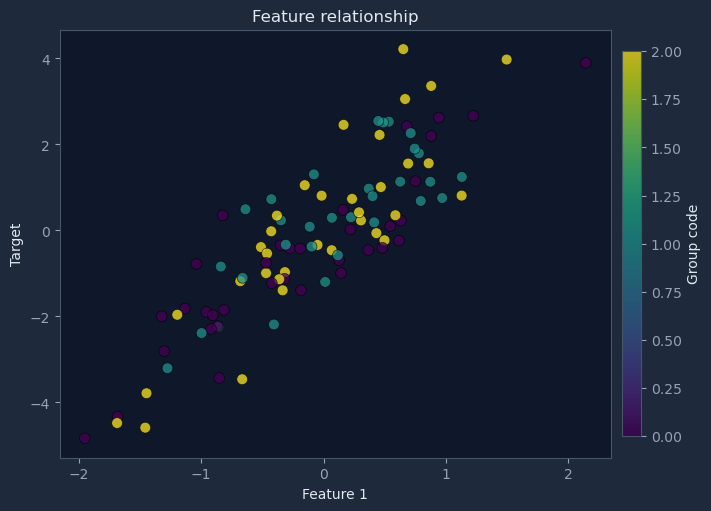

In [4]:
rng = np.random.default_rng(42)
x = rng.normal(size=100); y = 2*x + rng.normal(size=100); groups = rng.integers(0,3,100)
fig, ax = plt.subplots(figsize=(7,5), layout="constrained")
scatter = ax.scatter(
    x=x,                          # x: horizontal values
    y=y,                          # y: vertical values
    s=60,                         # s: marker area in points squared; scalar or array
    c=groups,                     # c: marker colors or numeric values mapped through cmap
    marker="o",                   # marker: marker shape
    cmap="viridis",               # cmap: colormap used when c contains numeric values
    norm=None,                    # norm: maps numeric c values to 0..1; None auto-scales
    alpha=0.75,                   # alpha: opacity
    linewidths=0.5,               # linewidths: marker edge thickness
    edgecolors="black",           # edgecolors: marker border color
    plotnonfinite=False           # plotnonfinite: whether invalid c values are plotted
)
fig.colorbar(scatter, ax=ax, label="Group code", shrink=0.9, pad=0.02)
# mappable: plotted object containing color mapping; ax: parent axes; label: colorbar label
# shrink: colorbar length multiplier; pad: gap from axes as a fraction
ax.set(xlabel="Feature 1", ylabel="Target", title="Feature relationship")
# set: compact setter; keyword names correspond to Axes properties
plt.show()


## 4. Bar charts


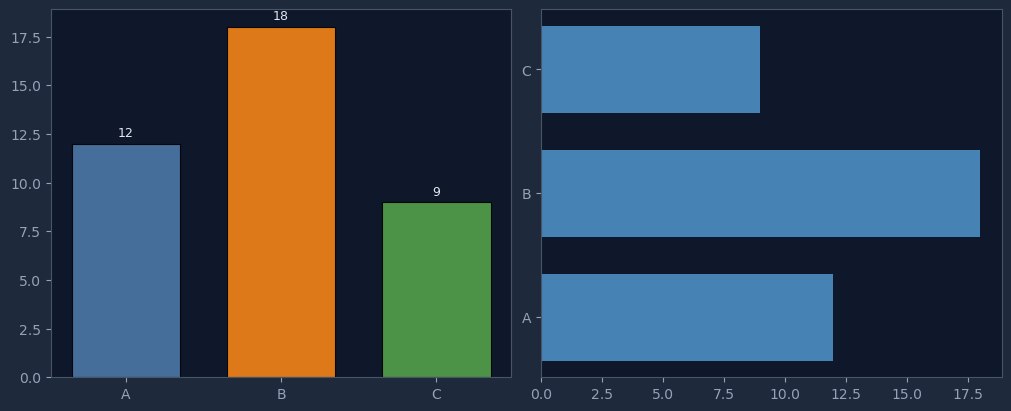

In [5]:
labels = ["A", "B", "C"]; values = [12, 18, 9]
fig, axes = plt.subplots(1,2,figsize=(10,4),layout="constrained")
bars = axes[0].bar(
    x=labels,                     # x: category positions or labels
    height=values,                # height: bar heights
    width=0.7,                    # width: width of each bar
    bottom=0,                     # bottom: y-coordinate where bars begin
    align="center",               # align: center or edge alignment relative to x
    color=["#4C78A8","#F58518","#54A24B"], # color: one color or one per bar
    edgecolor="black",            # edgecolor: border color
    linewidth=0.8,                # linewidth: border width
    alpha=0.9,                    # alpha: opacity
    label="Count"                 # label: legend text
)
axes[0].bar_label(bars, labels=None, fmt="%.0f", label_type="edge", padding=3, fontsize=9)
# container: bars returned by bar(); labels=None uses formatted values; fmt: number format
# label_type="edge": place at bar end; padding: spacing in points; fontsize: label size
axes[1].barh(y=labels, width=values, height=0.7, left=0, color="steelblue")
# y: category positions; width: horizontal bar lengths; height: bar thickness; left: starting x
plt.show()


## 5. Histogram


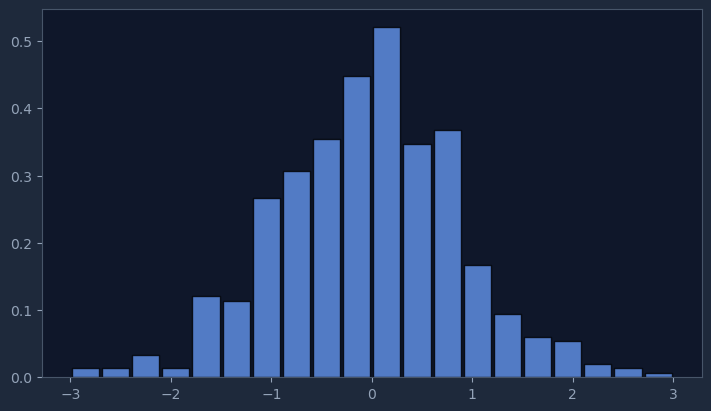

In [6]:
data = np.random.default_rng(1).normal(loc=0, scale=1, size=500)
fig, ax = plt.subplots(figsize=(7,4),layout="constrained")
counts, edges, patches = ax.hist(
    x=data,                       # x: input values or sequence of datasets
    bins=20,                      # bins: number of bins or explicit boundaries
    range=(-3,3),                 # range: lower/upper limits used to build bins
    density=True,                 # density=True normalizes area under histogram to 1
    weights=None,                 # weights: optional weight per observation
    cumulative=False,            # cumulative=True produces cumulative histogram
    histtype="bar",               # histtype: bar, barstacked, step, or stepfilled
    align="mid",                  # align: left, mid, or right alignment to bins
    orientation="vertical",       # orientation: vertical or horizontal
    rwidth=0.9,                   # rwidth: relative bar width inside each bin
    color="cornflowerblue",       # color: bar color
    edgecolor="black",            # edgecolor: border color
    alpha=0.8                     # alpha: opacity
)
plt.show()


## 6. Box plot and violin plot


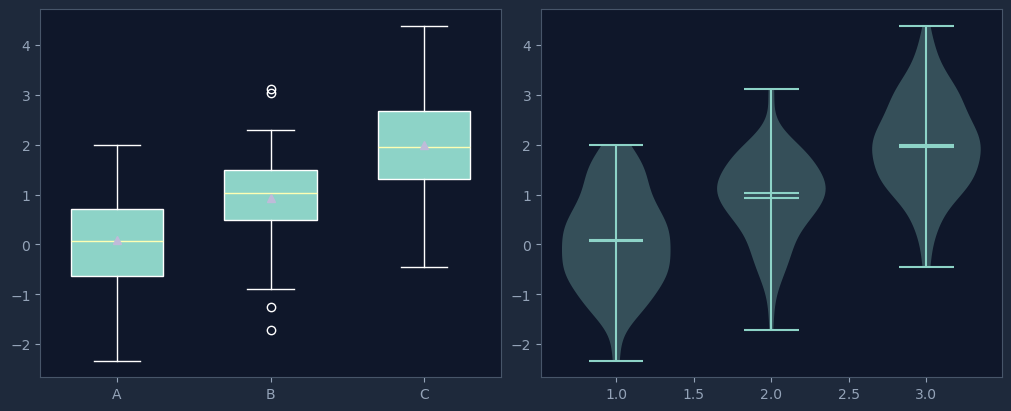

In [7]:
groups = [np.random.default_rng(i).normal(i,1,100) for i in range(3)]
fig, axes = plt.subplots(1,2,figsize=(10,4),layout="constrained")
axes[0].boxplot(
    x=groups,                     # x: sequence of datasets
    notch=False,                  # notch: show confidence-style notch around median
    vert=True,                    # vert: vertical boxes when True
    patch_artist=True,            # patch_artist: fill boxes when True
    widths=0.6,                   # widths: box widths
    showmeans=True,               # showmeans: display arithmetic mean marker
    showfliers=True,              # showfliers: display outlier points
    whis=1.5,                     # whis: whisker reach in IQR units or percentiles
    labels=["A","B","C"]        # labels: tick labels for datasets
)
axes[1].violinplot(
    dataset=groups,               # dataset: sequence of sample arrays
    positions=[1,2,3],            # positions: x positions of violins
    vert=True,                    # vert: vertical orientation
    widths=0.7,                   # widths: maximum violin width
    showmeans=True,               # showmeans: include mean line
    showextrema=True,             # showextrema: show minimum/maximum bars
    showmedians=True,             # showmedians: include median line
    quantiles=None,               # quantiles: optional quantile positions per dataset
    points=100,                   # points: KDE evaluation points
    bw_method="scott"             # bw_method: KDE bandwidth rule or scalar
)
plt.show()


## 7. Error bars and filled uncertainty


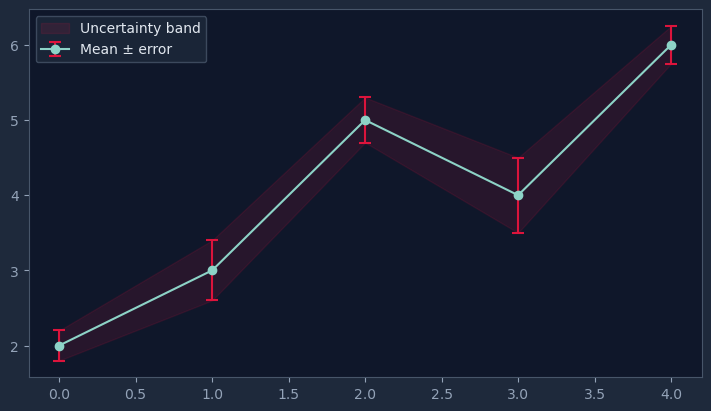

In [8]:
x=np.arange(5); mean=np.array([2,3,5,4,6]); error=np.array([.2,.4,.3,.5,.25])
fig,ax=plt.subplots(figsize=(7,4),layout="constrained")
ax.errorbar(
    x=x, y=mean,                  # x/y: point coordinates
    yerr=error,                   # yerr: symmetric or asymmetric vertical errors
    xerr=None,                    # xerr: optional horizontal errors
    fmt="o-",                     # fmt: compact marker/line style string
    ecolor="crimson",             # ecolor: error-bar color
    elinewidth=1.5,               # elinewidth: error-line thickness
    capsize=4,                    # capsize: error-bar cap length in points
    capthick=1.5,                 # capthick: cap thickness
    barsabove=False,              # barsabove: draw error bars above data when True
    label="Mean ± error"          # label: legend text
)
ax.fill_between(
    x=x,                          # x: shared horizontal coordinates
    y1=mean-error,                # y1: lower boundary
    y2=mean+error,                # y2: upper boundary
    where=None,                   # where: Boolean mask selecting filled intervals
    interpolate=False,            # interpolate: calculate actual crossing points when masked
    step=None,                    # step: pre/post/mid for step-shaped fill
    color="crimson", alpha=0.12, label="Uncertainty band"
)
ax.legend(); plt.show()


## 8. Images and heatmaps


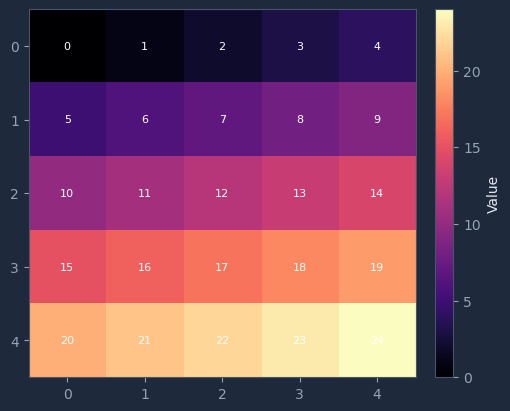

In [9]:
matrix = np.arange(25).reshape(5,5)
fig, ax = plt.subplots(figsize=(5,4),layout="constrained")
image = ax.imshow(
    X=matrix,                     # X: 2D scalar data or RGB(A) image array
    cmap="magma",                 # cmap: colormap for scalar data
    norm=None,                    # norm: value-to-color normalization
    aspect="auto",                # aspect: auto, equal, or a numeric height/width ratio
    interpolation="nearest",      # interpolation: pixel resampling method
    alpha=1.0,                    # alpha: opacity
    vmin=0, vmax=24,              # vmin/vmax: color scale limits when norm is None
    origin="upper",               # origin: put [0,0] at upper or lower left
    extent=None                   # extent: optional data coordinates [left,right,bottom,top]
)
fig.colorbar(image, ax=ax, label="Value")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(j,i,matrix[i,j],ha="center",va="center",color="white",fontsize=8)
plt.show()


## 9. Contour plot


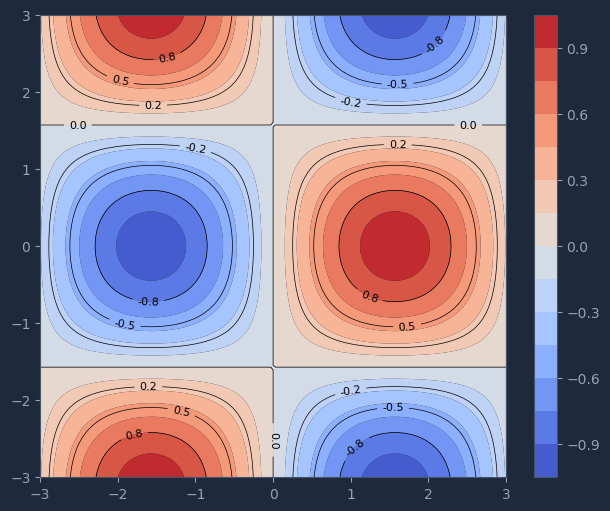

In [10]:
x=np.linspace(-3,3,100); y=np.linspace(-3,3,100); X,Y=np.meshgrid(x,y); Z=np.sin(X)*np.cos(Y)
fig,ax=plt.subplots(figsize=(6,5),layout="constrained")
filled=ax.contourf(
    X, Y, Z,                      # X,Y: coordinate grids; Z: height/value grid
    levels=15,                    # levels: number of contour levels or explicit values
    cmap="coolwarm",              # cmap: colormap
    norm=None,                    # norm: value normalization
    antialiased=True,             # antialiased: smooth polygon edges
    extend="neither"              # extend: color under/over values beyond levels
)
lines=ax.contour(X,Y,Z,levels=8,colors="black",linewidths=.5,linestyles="solid")
# colors: contour line colors; linewidths: thickness; linestyles: line pattern
ax.clabel(lines, inline=True, fontsize=8, fmt="%.1f")
# CS: contour set; inline: remove line behind labels; fontsize: size; fmt: label formatting
fig.colorbar(filled,ax=ax); plt.show()


## 10. Subplots and shared axes


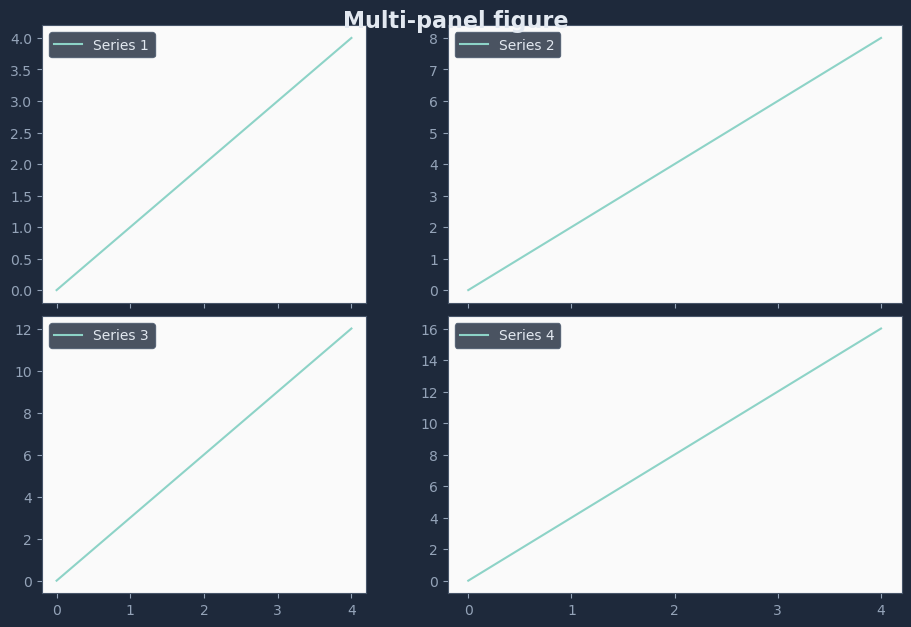

In [11]:
fig, axes = plt.subplots(
    nrows=2, ncols=2,             # create a 2-by-2 grid
    figsize=(9,6),
    sharex=True,                  # share x limits and ticks across subplots
    sharey=False,
    squeeze=True,                 # squeeze=True removes singleton dimensions from axes array
    width_ratios=[1,1.4],         # width_ratios: relative widths of subplot columns
    height_ratios=[1,1],          # height_ratios: relative heights of rows
    subplot_kw={"facecolor":"#fafafa"}, # subplot_kw: keyword arguments passed to each Axes
    gridspec_kw={"wspace":0.12},  # gridspec_kw: layout parameters for the underlying GridSpec
    layout="constrained"
)
for i, ax in enumerate(axes.flat):
    ax.plot(np.arange(5), np.arange(5)*(i+1), label=f"Series {i+1}")
    ax.legend()
fig.suptitle("Multi-panel figure", x=0.5, y=1.02, fontsize=16, fontweight="bold")
# t: title text; x/y: figure-relative location; fontsize/fontweight: appearance
plt.show()


## 11. Axis limits, ticks, scales, and formatters


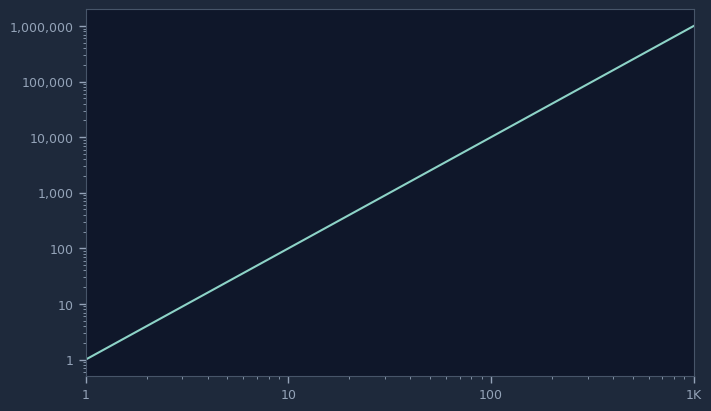

In [12]:
x=np.logspace(0,3,50); y=x**2
fig,ax=plt.subplots(figsize=(7,4),layout="constrained")
ax.plot(x,y)
ax.set_xscale("log", base=10)     # value: scale type; base: logarithm base
ax.set_yscale("log", base=10)
ax.set_xlim(left=1, right=1000, emit=True, auto=False)
# left/right: limits; emit: notify observers; auto=False disables autoscaling on this axis
ax.set_xticks([1,10,100,1000], labels=["1","10","100","1K"], minor=False)
# ticks: positions; labels: displayed labels; minor: target minor ticks when True
ax.tick_params(axis="both", which="major", direction="out", length=5, width=1, labelsize=9, rotation=0)
# axis: x/y/both; which: major/minor/both; direction: in/out/inout
# length/width: tick dimensions; labelsize: tick-label size; rotation: label rotation
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda value,pos:f"{value:,.0f}"))
# FuncFormatter receives numeric value and tick position and returns a string
plt.show()


## 12. Annotations


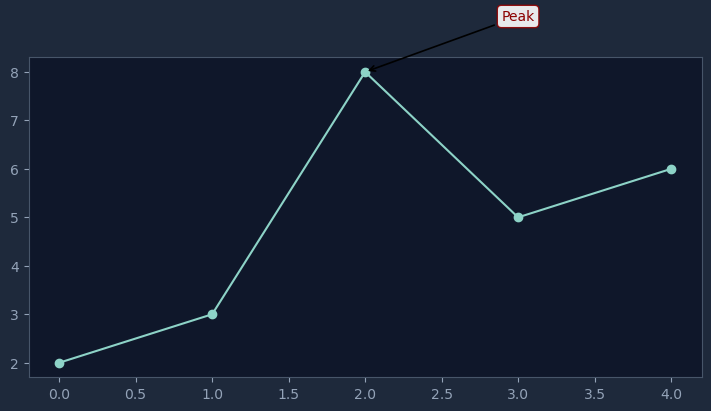

In [13]:
x=np.arange(5); y=np.array([2,3,8,5,6])
fig,ax=plt.subplots(figsize=(7,4),layout="constrained"); ax.plot(x,y,marker="o")
ax.annotate(
    text="Peak",                  # text: annotation text
    xy=(2,8),                     # xy: data point being annotated
    xytext=(3,9),                 # xytext: text position
    xycoords="data",              # xycoords: coordinate system used for xy
    textcoords="data",            # textcoords: coordinate system used for xytext
    arrowprops={"arrowstyle":"->","color":"black","lw":1.2}, # arrowprops: arrow style dictionary
    ha="center", va="bottom",     # horizontal and vertical alignment
    fontsize=10, color="darkred", # text appearance
    bbox={"boxstyle":"round,pad=0.3","fc":"white","ec":"darkred","alpha":0.9}
    # bbox: text bounding-box properties
)
plt.show()


## 13. Saving and closing figures


In [14]:
fig, ax = plt.subplots(figsize=(5,3),layout="constrained")
ax.plot([1,2,3],[1,4,9]); ax.set_title("Saved figure example")
# fig.savefig(
#     fname="figure.png",          # fname: destination path; extension determines format
#     dpi=300,                     # dpi: raster resolution
#     facecolor="white",           # facecolor: saved figure background
#     edgecolor="none",            # edgecolor: saved figure border color
#     orientation="portrait",      # orientation: mainly used by PostScript output
#     format="png",                # format: explicit output format; usually inferred from extension
#     transparent=False,           # transparent=True makes background transparent
#     bbox_inches="tight",         # bbox_inches="tight" crops extra whitespace
#     pad_inches=0.1,              # pad_inches: padding around tight bounding box
#     metadata={"Title":"Example"} # metadata: format-dependent file metadata
# )
plt.show()
plt.close(fig)                     # Close this figure and release memory


## 14. AI/ML visualization patterns


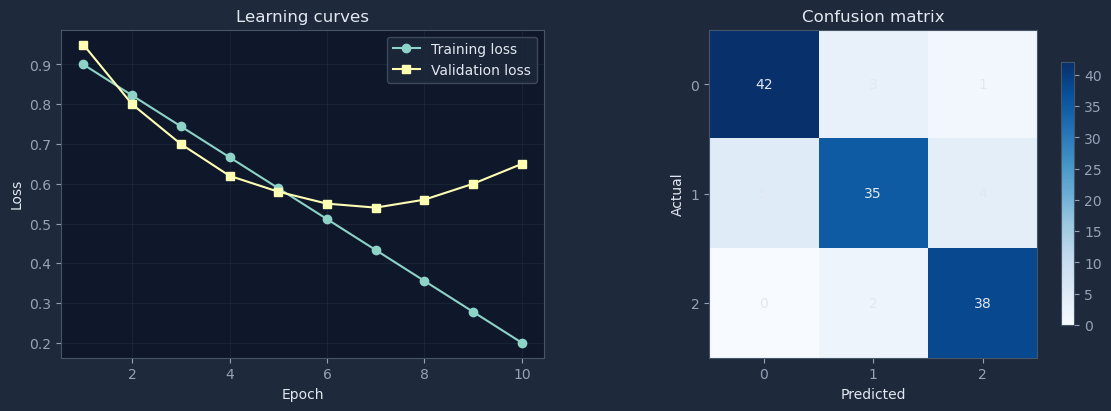

In [15]:
epochs=np.arange(1,11); train=np.linspace(.9,.2,10); val=np.array([.95,.8,.7,.62,.58,.55,.54,.56,.6,.65])
fig,axes=plt.subplots(1,2,figsize=(11,4),layout="constrained")
axes[0].plot(epochs,train,label="Training loss",marker="o")
axes[0].plot(epochs,val,label="Validation loss",marker="s")
axes[0].set(xlabel="Epoch",ylabel="Loss",title="Learning curves")
axes[0].legend(); axes[0].grid(alpha=.3)

cm=np.array([[42,3,1],[5,35,4],[0,2,38]])
im=axes[1].imshow(cm,cmap="Blues",vmin=0,vmax=cm.max())
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[1].text(j,i,cm[i,j],ha="center",va="center")
axes[1].set(xticks=range(3),yticks=range(3),xlabel="Predicted",ylabel="Actual",title="Confusion matrix")
fig.colorbar(im,ax=axes[1],shrink=.8); plt.show()


## Final Matplotlib checklist

Master the object-oriented workflow, lines, scatter, bars, histogram, distributions, uncertainty, images/heatmaps, subplots, labels, legends, scales, annotations, and export. For AI work, repeatedly use learning curves, feature distributions, residual plots, confusion matrices, ROC/PR curves, and prediction-versus-actual charts.
